# Practice Session: Machine-Learned Interatomic Potentials from Scratch

**Companion to the class notes "Machine-Learned Interatomic Potentials".**

In this session we build a complete, working MLIP with nothing more than NumPy and Matplotlib. Every step from the notes appears here as runnable code:

| Part | Topic | Notes section |
|---|---|---|
| 1 | Potential energy surface, forces, finite-difference check | §1, §2 |
| 2 | A one-dimensional toy MLIP: basis size, overfitting, extrapolation | §6 |
| 3 | Cutoff functions and smoothness | §3.3 |
| 4 | Symmetry: why raw coordinates fail, Behler symmetry functions | §3.2, §4 |
| 5 | Equivariance and the ACE "density trick" | §10, §12 |
| 6 | Generating a reference dataset by molecular dynamics | §8 |
| 7 | Fitting a linear Behler–Parrinello-type MLIP on energies and forces | §4, §6, §8 |
| 8 | Running molecular dynamics with the MLIP | §14 |
| 9 | Extrapolation and failure modes | §6 |

**Units.** Apart from Part 1, all quantities are in Lennard-Jones reduced units: energy in $\epsilon$, length in $\sigma$, mass $m=1$, time $\tau=\sigma\sqrt{m/\epsilon}$, temperature in $\epsilon/k_B$.

**How to use the notebook.** Run the cells in order. Cells marked **Try it** invite small changes. The full notebook runs in about one to two minutes on a laptop.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time

plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(2026)
print("NumPy", np.__version__)

NumPy 2.1.3


---
## Part 1. The potential energy surface and its forces

The reference "quantum" PES in this session is a model potential. Using a known function as the reference lets us measure the error of the MLIP exactly, which is impossible with real DFT data.

We start with the Lennard-Jones (LJ) pair potential

$$
U(r) = 4\epsilon\left[\left(\frac{\sigma}{r}\right)^{12}-\left(\frac{\sigma}{r}\right)^{6}\right],\qquad
E=\sum_{i<j}U(r_{ij}),
$$

- $r_{ij}=|\mathbf r_j-\mathbf r_i|$ is the distance between atoms $i$ and $j$,
- $\epsilon$ is the well depth and $\sigma$ the distance where $U=0$,
- the sum over $i<j$ counts each pair once.

The force on atom $i$ is $\mathbf F_i=-\nabla_{\mathbf r_i}E$. By the chain rule, with $\mathbf d_{ij}=\mathbf r_j-\mathbf r_i$,

$$
\mathbf F_i = \sum_{j\neq i} U'(r_{ij})\,\frac{\mathbf d_{ij}}{r_{ij}},\qquad
U'(r)=\frac{4\epsilon}{r}\left[-12\left(\frac{\sigma}{r}\right)^{12}+6\left(\frac{\sigma}{r}\right)^{6}\right].
$$

When $U'(r)>0$ (attractive region, $r>r_m$) the force on $i$ points towards $j$. When $U'(r)<0$ (repulsive wall) it points away.

In [2]:
def pair_geometry(R):
    # D[i, j] = r_j - r_i  (shape N x N x 3) and the distance matrix r[i, j]
    D = R[None, :, :] - R[:, None, :]
    r = np.linalg.norm(D, axis=-1)
    return D, r

def lj_energy(R, eps=1.0, sig=1.0):
    _, r = pair_geometry(R)
    iu = np.triu_indices(len(R), 1)          # pairs with i < j
    x6 = (sig / r[iu])**6
    return np.sum(4 * eps * (x6 * x6 - x6))

def lj_forces(R, eps=1.0, sig=1.0):
    D, r = pair_geometry(R)
    np.fill_diagonal(r, np.inf)              # no self-interaction
    x6 = (sig / r)**6
    dU = 4 * eps * (-12 * x6 * x6 + 6 * x6) / r      # U'(r)
    return np.sum((dU / r)[:, :, None] * D, axis=1)  # F_i = sum_j U' d_ij / r_ij

### Example 1 : the argon dimer
Classic argon parameters are $\epsilon = 0.0104$ eV and $\sigma = 3.40$ Å. The minimum lies at $r_m = 2^{1/6}\sigma$ with $U(r_m)=-\epsilon$.

r_m = 3.816 A,  U(r_m) = -10.40 meV
r = 3.5 A   U =   -5.58 meV   F(atom 2) = +0.0408 eV/A
r = 4.0 A   U =   -9.77 meV   F(atom 2) = -0.0058 eV/A
r = 5.0 A   U =   -3.71 meV   F(atom 2) = -0.0040 eV/A


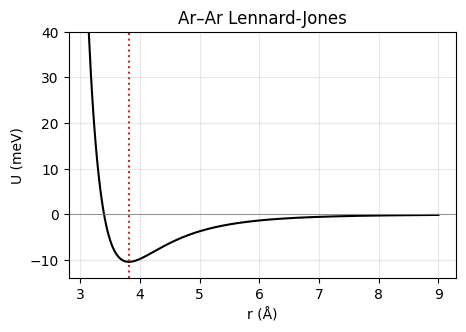

In [3]:
eps_Ar, sig_Ar = 0.0104, 3.40
rm = 2**(1/6) * sig_Ar
print(f"r_m = {rm:.3f} A,  U(r_m) = {1000*lj_energy(np.array([[0,0,0],[rm,0,0]]), eps_Ar, sig_Ar):.2f} meV")

for r in (3.5, 4.0, 5.0):
    R = np.array([[0.0, 0, 0], [r, 0, 0]])
    E = lj_energy(R, eps_Ar, sig_Ar)
    Fx_on_atom2 = lj_forces(R, eps_Ar, sig_Ar)[1, 0]   # positive = pushed away from atom 1
    print(f"r = {r:.1f} A   U = {1000*E:7.2f} meV   F(atom 2) = {Fx_on_atom2:+.4f} eV/A")

rgrid = np.linspace(3.1, 9, 300)
U = [lj_energy(np.array([[0,0,0],[x,0,0]]), eps_Ar, sig_Ar) for x in rgrid]
plt.figure(figsize=(5, 3.2))
plt.plot(rgrid, 1000*np.array(U), "k")
plt.axhline(0, color="gray", lw=0.6); plt.axvline(rm, ls=":", color="C3")
plt.ylim(-14, 40); plt.xlabel("r (Å)"); plt.ylabel("U (meV)"); plt.title("Ar–Ar Lennard-Jones")
plt.show()

### Always check analytic forces with finite differences
Wrong forces are the most common bug in any force-field code. The central difference

$$
F_{i\alpha}\approx-\frac{E(\mathbf r_{i\alpha}+h)-E(\mathbf r_{i\alpha}-h)}{2h}
$$

has an error of order $h^2$. We will also use this function later to obtain forces for terms where an analytic derivative is tedious to code.

In [4]:
def numerical_forces(energy_fn, R, h=1e-5):
    F = np.zeros_like(R)
    for i in range(R.shape[0]):
        for a in range(3):
            Rp = R.copy(); Rp[i, a] += h
            Rm = R.copy(); Rm[i, a] -= h
            F[i, a] = -(energy_fn(Rp) - energy_fn(Rm)) / (2 * h)
    return F

grid = np.array([[i, j, k] for i in (0, 1) for j in (0, 1) for k in (0, 1)], float) * 1.1
R_test = grid + rng.normal(scale=0.08, size=grid.shape)      # slightly distorted cube of 8 atoms
err = np.abs(lj_forces(R_test) - numerical_forces(lj_energy, R_test)).max()
print(f"max |F_analytic - F_numerical| = {err:.2e}   (largest force = {np.abs(lj_forces(R_test)).max():.1f})")

max |F_analytic - F_numerical| = 2.96e-07   (largest force = 62.8)


---
## Part 2. The smallest possible MLIP: a one-dimensional linear fit

Before handling three-dimensional clusters, we fit the argon dimer curve with a **linear model in a fixed basis**, exactly as in §6 of the notes:

$$
E(r)=\sum_{\beta=0}^{K-1}c_\beta\,Q_\beta(r),\qquad
Q_\beta(r)=T_\beta\!\left(\tfrac{2(r-r_{\min})}{r_c-r_{\min}}-1\right)(r_c-r)^2 .
$$

- $T_\beta$ is the Chebyshev polynomial of order $\beta$, defined on $[-1,1]$, so the distance is first rescaled to that interval.
- $(r_c-r)^2$ is the MTP-style cutoff factor. Every basis function, and therefore the model, goes to zero at $r_c$.
- $c_\beta$ are the coefficients we learn.

Because the model is linear in $c_\beta$, training is ordinary least squares. With the design matrix $X_{k\beta}=Q_\beta(r_k)$ and labels $y_k=E_k$,

$$
\mathbf c=\arg\min_{\mathbf c}\|X\mathbf c-\mathbf y\|^2=(X^{\mathsf T}X)^{-1}X^{\mathsf T}\mathbf y .
$$

MTP, SNAP and linear ACE are trained in exactly the same way, only with many-body basis functions instead of $Q_\beta(r)$.

In [30]:
def U_Ar(r):  # reference curve (eV)
    return 4 * eps_Ar * ((sig_Ar / r)**12 - (sig_Ar / r)**6)

r_min, r_cut = 3.0, 8.0
def cheb_basis(r, K):
    x = 2 * (r - r_min) / (r_cut - r_min) - 1
    return np.polynomial.chebyshev.chebvander(x, K - 1) * ((r_cut - r)**2)[:, None]

rng1 = np.random.default_rng(0)
r_train = rng1.uniform(2.9, 7.5, 40);  E_train = U_Ar(r_train)
r_test  = np.linspace(3.25, 7.5, 200); E_test  = U_Ar(r_test)

print(" K   train RMSE (meV)   test RMSE (meV)   max test error (meV)")
for K in (2, 4, 6, 8, 10):
    X = cheb_basis(r_train, K)
    c, *_ = np.linalg.lstsq(X, E_train, rcond=None)     # numerically stable least squares
    tr = 1000 * np.sqrt(np.mean((X @ c - E_train)**2))
    pred = cheb_basis(r_test, K) @ c
    te = 1000 * np.sqrt(np.mean((pred - E_test)**2))
    print(f"{K:2d}   {tr:12.3f}       {te:12.3f}       {1000*np.abs(pred - E_test).max():12.3f}")

 K   train RMSE (meV)   test RMSE (meV)   max test error (meV)
 2         19.945             19.770             48.896
 4          8.083              6.895             21.805
 6          2.909              2.151              4.965
 8          0.564              0.811              2.237
10          0.100              0.138              0.676


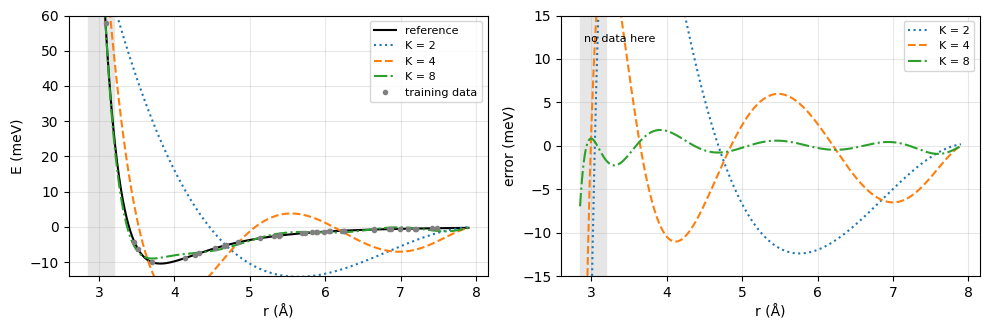

K=8 at r = 3.00 A: model   99.5 meV, true   98.7 meV, error +1 %
K=8 at r = 2.80 A: model  277.2 meV, true  294.1 meV, error -6 %


In [34]:
r_plot = np.linspace(2.85, 7.9, 400)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(r_plot, 1000 * U_Ar(r_plot), "k", lw=1.5, label="reference")
for K, st in [(2, ":"), (4, "--"), (8, "-.")]:
    c, *_ = np.linalg.lstsq(cheb_basis(r_train, K), E_train, rcond=None)
    p = cheb_basis(r_plot, K) @ c
    ax[0].plot(r_plot, 1000 * p, st, label=f"K = {K}")
    ax[1].plot(r_plot, 1000 * (p - U_Ar(r_plot)), st, label=f"K = {K}")
ax[0].plot(r_train, 1000 * E_train, "o", ms=3, color="gray", label="training data")
for a in ax:
    a.axvspan(2.85, 3.2, color="0.9"); a.set_xlabel("r (Å)")
ax[0].set_ylim(-14, 60); ax[0].set_ylabel("E (meV)"); ax[0].legend(fontsize=8)
ax[1].set_ylim(-15, 15); ax[1].set_ylabel("error (meV)"); ax[1].legend(fontsize=8)
ax[1].text(2.9, 12, "no data here", fontsize=8)
plt.tight_layout(); plt.show()

c8, *_ = np.linalg.lstsq(cheb_basis(r_train, 8), E_train, rcond=None)
for r in (3.0, 2.8):
    p, t = (cheb_basis(np.array([r]), 8) @ c8)[0], U_Ar(r)
    print(f"K=8 at r = {r:.2f} A: model {1000*p:6.1f} meV, true {1000*t:6.1f} meV, error {100*(p-t)/t:+.0f} %")

**What to notice.**
1. A larger basis lowers both training and test error, **as long as the test points lie inside the training range**.
2. On the grey band (shorter distances than any training point) the $K=8$ model underestimates the repulsive wall by 11 to 26 %, although its in-range error is below 0.4 meV. Underestimated repulsion lets atoms approach each other too closely during MD, and the simulation "explodes".

**Try it.** Change the training range to `uniform(2.9, 7.5, 40)` and rerun. How does the extrapolation error change?

### Effect of Changing the Training Range on Extrapolation

When the training range is expanded from the original interval of [3.2, 7.5] down to [2.9, 7.5] (including the highly repulsive region of the potential):

1. Drastic Reduction in Extrapolation Error:
   Previously, because the model had no training data below $3.2$ , the $K=8$ fit underestimated the repulsive wall at shorter distances (e.g., yielding significant errors at $3.0$ and $2.8$).
   By shifting the training boundary to $2.9$, the model directly learns the steep slope of the repulsive wall. The prediction error at $3.0$ Å drops from around +11% (or worse) to less than 1%

2. Shifted Boundary of Failure:
   Extrapolation still fails eventually, but the boundary of failure is pushed further in. Predictions at $2.8$ (which is now just outside the new $2.9$ training limit) remain much more stable than they were under the original training set, reducing the likelihood of atomic overlap and simulation 'explosions' during MD.

---
## Part 3. Cutoff functions

A local MLIP only looks at neighbours within a cutoff $r_c$. If a neighbour's contribution dropped abruptly to zero at $r_c$, the energy would jump whenever an atom crossed the sphere and total energy would not be conserved in MD. Every radial term is therefore multiplied by a smooth cutoff function:

$$
f_c^{\cos}(r)=\tfrac12\left[\cos\left(\frac{\pi r}{r_c}\right)+1\right],\qquad
f_{\rm env}(x)=1-\tfrac{(p+1)(p+2)}{2}x^p+p(p+2)x^{p+1}-\tfrac{p(p+1)}{2}x^{p+2},\quad x=\frac{r}{r_c},
$$

both set to zero for $r\ge r_c$. The cosine form (Behler) has zero slope at $r_c$. The polynomial envelope (DimeNet, NequIP, MACE) with $p=6$ has zero value, slope and curvature at $r_c$.

cosine       : f(0) = 1.000, f(rc) = 0.0e+00, slope near rc = -3.9e-05, curvature near rc = +0.197
envelope p=6 : f(0) = 1.000, f(rc) = 0.0e+00, slope near rc = -5.8e-08, curvature near rc = +0.001


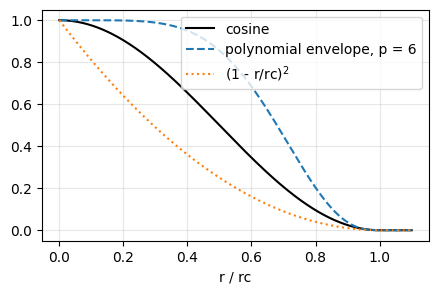

In [35]:
def fc_cos(r, rc):
    return np.where(r < rc, 0.5 * (np.cos(np.pi * np.minimum(r, rc) / rc) + 1.0), 0.0)

def f_env(r, rc, p=6):
    x = np.minimum(r / rc, 1.0)
    val = 1 - (p+1)*(p+2)/2 * x**p + p*(p+2) * x**(p+1) - p*(p+1)/2 * x**(p+2)
    return np.where(r < rc, val, 0.0)

rc = 5.0; h = 1e-4
for name, f in [("cosine", fc_cos), ("envelope p=6", f_env)]:
    d1 = (f(rc - h, rc) - f(rc - 3*h, rc)) / (2*h)                   # one-sided slope just inside rc
    d2 = (f(rc - h, rc) - 2*f(rc - 2*h, rc) + f(rc - 3*h, rc)) / h**2  # curvature just inside rc
    print(f"{name:13s}: f(0) = {float(f(0.0, rc)):.3f}, f(rc) = {float(f(rc, rc)):.1e}, "
          f"slope near rc = {float(d1):+.1e}, curvature near rc = {float(d2):+.3f}")

x = np.linspace(0, 1.1, 300)
plt.figure(figsize=(5, 3))
plt.plot(x, fc_cos(x, 1.0), "k", label="cosine")
plt.plot(x, f_env(x, 1.0), "--", label="polynomial envelope, p = 6")
plt.plot(x, np.where(x < 1, (1 - x)**2, 0), ":", label="(1 - r/rc)$^2$")
plt.xlabel("r / rc"); plt.legend(); plt.show()

The cosine cutoff has zero slope but nonzero curvature ($\pi^2/2r_c^2\approx0.197$ for $r_c=5$) at $r_c$, whereas the envelope also has zero curvature. Smoother cutoffs give smoother forces and better energy conservation.

---
## Part 4. Symmetry and atom-centred symmetry functions

### 4.1 Why raw coordinates are a bad input
The energy must be invariant under translation, rotation, reflection and permutation of identical atoms. Cartesian coordinates change under all of these operations, even though the energy does not.

In [36]:
def random_rotation(rng):
    # QR decomposition of a Gaussian matrix gives a uniformly random orthogonal matrix
    Q, Rq = np.linalg.qr(rng.normal(size=(3, 3)))
    Q = Q @ np.diag(np.sign(np.diag(Rq)))
    if np.linalg.det(Q) < 0:
        Q[:, 0] *= -1                                     # make it a proper rotation
    return Q

R = R_test.copy()                                         # the distorted 8-atom cube from Part 1
Q = random_rotation(rng); t = np.array([3.0, -1.0, 0.5]); perm = rng.permutation(len(R))
R_rot, R_tr, R_perm = R @ Q.T, R + t, R[perm]

print("energy  original / rotated / translated / permuted:")
print(["%.8f" % lj_energy(x) for x in (R, R_rot, R_tr, R_perm)])
print("\nfirst row of coordinates, original vs rotated:", R[0].round(3), R_rot[0].round(3))

energy  original / rotated / translated / permuted:
['-10.71782904', '-10.71782904', '-10.71782904', '-10.71782904']

first row of coordinates, original vs rotated: [-0.063  0.019 -0.152] [0.004 0.161 0.039]


A regressor fed raw coordinates would have to *learn* all these symmetries from data. The solution is to use **descriptors** that are invariant by construction.

### 4.2 Behler–Parrinello symmetry functions

Radial function:
$$
G_i^{2}=\sum_{j\ne i}e^{-\eta(r_{ij}-R_s)^2}f_c(r_{ij})
$$
- $\eta$: width of the Gaussian shell, $R_s$: its centre. A set of $(\eta,R_s)$ pairs gives a smooth histogram of neighbour distances.

Angular function (triplets $j$–$i$–$k$, angle $\theta_{ijk}$ at atom $i$):
$$
G_i^{4}=2^{1-\zeta}\sum_{j<k}\ (1+\lambda\cos\theta_{ijk})^{\zeta}\,e^{-\eta(r_{ij}^2+r_{ik}^2+r_{jk}^2)}f_c(r_{ij})f_c(r_{ik})f_c(r_{jk})
$$
- $\lambda=\pm1$ places the maximum at $0^\circ$ or $180^\circ$, $\zeta$ controls angular sharpness.
- We count each unordered pair $\{j,k\}$ once (as in Example 3 of the notes). Some codes sum over ordered pairs, which simply doubles $G^4$.

Both functions use only distances and dot products of bond vectors, so they are rotation and translation invariant. Each is a sum over neighbours, so it is permutation invariant.

The implementation below is fully vectorised. For atom $i$ we build all triplets at once with `einsum`.

In [37]:
def g2_atoms(R, etas, Rss, rc):
    # returns G2 for every atom: shape (N, n_G2)
    _, r = pair_geometry(R)
    np.fill_diagonal(r, np.inf)
    f = fc_cos(r, rc)
    G = np.exp(-etas[None, None, :] * (r[:, :, None] - Rss[None, None, :])**2) * f[:, :, None]
    return G.sum(axis=1)

def g4_atoms(R, params, rc):
    # params: list of (eta, zeta, lam).  returns shape (N, len(params))
    D, r = pair_geometry(R)
    N = len(R)
    np.fill_diagonal(r, np.inf)
    f = fc_cos(r, rc)
    u = D / r[:, :, None]                                   # unit bond vectors (zero on diagonal)
    cos = np.einsum("ijx,ikx->ijk", u, u)                   # cos(theta_jik) at atom i
    r2 = np.where(np.isinf(r), 0.0, r)**2
    rsum = r2[:, :, None] + r2[:, None, :] + r2[None, :, :]  # r_ij^2 + r_ik^2 + r_jk^2
    fff = f[:, :, None] * f[:, None, :] * f[None, :, :]
    idx = np.arange(N)
    out = []
    for eta, zeta, lam in params:
        t = 2.0**(1 - zeta) * (1 + lam * cos)**zeta * np.exp(-eta * rsum) * fff
        t[:, idx, idx] = 0.0                                # remove j = k
        out.append(0.5 * t.sum(axis=(1, 2)))                # 0.5: count {j,k} once
    return np.stack(out, axis=1)

### 4.3 Reproduce Example 3 of the notes
Atom $i$ at the origin, $r_{ij}=1.0$ Å, $r_{ik}=1.5$ Å, angle $104.5^\circ$, $r_c=5$ Å. The notes give $G^2=0.806$ ($\eta=0.5$, $R_s=0$), and $G^4=0.171$ ($\lambda=+1$) and $0.285$ ($\lambda=-1$) for $\eta=0.1,\ \zeta=1$.

In [38]:
th = np.deg2rad(104.5)
R3 = np.array([[0, 0, 0], [1.0, 0, 0], [1.5*np.cos(th), 1.5*np.sin(th), 0]])
print("G2       :", g2_atoms(R3, np.array([0.5]), np.array([0.0]), 5.0)[0].round(4))
print("G4 (l=+1, l=-1):", g4_atoms(R3, [(0.1, 1, +1), (0.1, 1, -1)], 5.0)[0].round(4))

G2       : [0.8064]
G4 (l=+1, l=-1): [0.1706 0.2846]


### 4.4 Invariance test
We apply a random rotation, a translation and a permutation, then compare descriptors. For the permutation the **set** of atomic descriptor vectors must be the same, only reordered.

In [39]:
etas = np.full(8, 4.0); Rss = np.linspace(0.8, 2.4, 8); g4p = [(0.5, z, l) for z in (1, 4) for l in (1, -1)]
desc = lambda X: np.hstack([g2_atoms(X, etas, Rss, 2.5), g4_atoms(X, g4p, 2.5)])

G_ref = desc(R)
print("rotation    :", np.abs(desc(R_rot) - G_ref).max())
print("translation :", np.abs(desc(R_tr)  - G_ref).max())
print("permutation :", np.abs(desc(R_perm) - G_ref[perm]).max())

rotation    : 8.881784197001252e-16
translation : 1.1102230246251565e-15
permutation : 6.661338147750939e-16


---
## Part 5. Equivariance and the ACE density trick

### 5.1 An $l=1$ feature rotates, its square does not
Equivariant models carry vectors (and higher tensors) as features. The simplest is the $l=1$ projection of the neighbour density,

$$
A_{0}=\frac{1}{\sqrt{4\pi}}\sum_j R(r_{ij}),\qquad
\mathbf A_{1}=\sqrt{\frac{3}{4\pi}}\sum_j R(r_{ij})\,\hat{\mathbf r}_{ij},
$$

using real spherical harmonics $Y_{00}=1/\sqrt{4\pi}$ and $Y_{1}(\hat{\mathbf r})=\sqrt{3/4\pi}\,\hat{\mathbf r}$.

- $A_0$ is a scalar: **invariant**, $A_0(Q\mathbf R)=A_0(\mathbf R)$.
- $\mathbf A_1$ is a vector: **equivariant**, $\mathbf A_1(Q\mathbf R)=Q\,\mathbf A_1(\mathbf R)$.
- $|\mathbf A_1|^2=\sum_m A_{1m}^2$ is invariant and equals the $l=1$ power spectrum (SOAP) and the $\nu=2$ ACE invariant.

We reproduce Example 8 of the notes: a bent triatomic, two neighbours at 0.96 Å, angle 104.5°, $R(r)=f_c^{\cos}(r)$ with $r_c=5$ Å.

In [40]:
def A0_A1(Rnb, rc=5.0):
    # Rnb: neighbour vectors r_ij relative to the central atom (shape M x 3)
    d = np.linalg.norm(Rnb, axis=1)
    Rr = fc_cos(d, rc)
    A0 = Rr.sum() / np.sqrt(4*np.pi)
    A1 = np.sqrt(3/(4*np.pi)) * (Rr[:, None] * Rnb / d[:, None]).sum(axis=0)
    return A0, A1

th = np.deg2rad(104.5)
nb = np.array([[0.96, 0, 0], [0.96*np.cos(th), 0.96*np.sin(th), 0]])
A0, A1 = A0_A1(nb)
Qr = random_rotation(np.random.default_rng(5))
A0r, A1r = A0_A1(nb @ Qr.T)
print(f"A0  before / after rotation: {A0:.4f} / {A0r:.4f}")
print("A1 after rotation        :", A1r.round(4))
print("Q @ A1 (before rotation) :", (Qr @ A1).round(4))
print(f"|A1|^2 before / after: {A1 @ A1:.4f} / {A1r @ A1r:.4f}")

# addition theorem: |A1|^2 = 3/(4 pi) sum_{j,k} R_j R_k cos(theta_jk)   (a 3-body sum)
Rj = fc_cos(np.linalg.norm(nb, axis=1), 5.0)
U = nb / np.linalg.norm(nb, axis=1)[:, None]
print(f"3-body sum via angles: {3/(4*np.pi) * np.sum(np.outer(Rj, Rj) * (U @ U.T)):.4f}")

A0  before / after rotation: 0.5144 / 0.5144
A1 after rotation        : [0.3316 0.2525 0.3519]
Q @ A1 (before rotation) : [0.3316 0.2525 0.3519]
|A1|^2 before / after: 0.2975 / 0.2975
3-body sum via angles: 0.2975


### 5.2 The density trick that makes ACE cheap
A $(\nu+1)$-body sum over neighbours costs $N_{\rm nb}^{\nu}$ operations if done directly. ACE instead computes the atomic basis $A=\sum_j\phi(r_{ij})$ once ($N_{\rm nb}$ operations) and uses

$$
A^{\nu}=\Big(\sum_j\phi_j\Big)^{\nu}=\sum_{j_1}\cdots\sum_{j_\nu}\phi_{j_1}\cdots\phi_{j_\nu}.
$$

Below we compare both routes for a 4-body term ($\nu=3$) with 60 neighbours.

In [41]:
phi = np.exp(-rng.uniform(1.0, 5.0, 60))          # phi(r_ij) for 60 neighbours

t0 = time.perf_counter()
direct = sum(a*b*c for a in phi for b in phi for c in phi)   # N_nb^3 = 216 000 products
t1 = time.perf_counter()
A = phi.sum(); ace = A**3                                     # 60 additions + 2 multiplications
t2 = time.perf_counter()
print(f"direct triple sum : {direct:.10f}   ({1e3*(t1-t0):.1f} ms)")
print(f"ACE  (sum phi)^3  : {ace:.10f}   ({1e6*(t2-t1):.1f} us)")

direct triple sum : 207.5011435099   (79.0 ms)
ACE  (sum phi)^3  : 207.5011435099   (283.2 us)


---
## Part 6. A reference dataset from molecular dynamics

### 6.1 The reference potential
A pure pair potential could be learned with radial descriptors alone. To make angular information **necessary**, our reference ("DFT") adds a three-body term that prefers tetrahedral angles:

$$
E_{\rm ref}=\sum_{i<j}U_{\rm LJ}(r_{ij})\;+\;\frac{K}{2}\sum_i\sum_{j\ne k}\big(\cos\theta_{jik}-c_0\big)^2 g(r_{ij})\,g(r_{ik}),
$$

- $K=0.6\,\epsilon$: strength of the angular term,
- $c_0=-1/3$: cosine of the tetrahedral angle $109.47^\circ$,
- $g(r)=f_c^{\cos}(r;\,1.6\sigma)$: restricts the angular term to the first coordination shell,
- the factor $\tfrac12$ counts each unordered pair $\{j,k\}$ once.

The three-body term resembles the Stillinger–Weber potential for silicon. Forces for the LJ part are analytic. For the three-body term we use the finite-difference routine from Part 1 (in real work, DFT supplies analytic forces).

In [42]:
def three_body_energy(R, K=0.6, c0=-1/3, rc3=1.6):
    D, r = pair_geometry(R)
    N = len(R)
    np.fill_diagonal(r, np.inf)
    g = fc_cos(r, rc3)
    u = D / r[:, :, None]
    cos = np.einsum("ijx,ikx->ijk", u, u)
    t = (cos - c0)**2 * g[:, :, None] * g[:, None, :]
    idx = np.arange(N); t[:, idx, idx] = 0.0
    return 0.5 * K * t.sum()

def ref_energy(R):
    return lj_energy(R) + three_body_energy(R)

def ref_forces(R):
    return lj_forces(R) + numerical_forces(three_body_energy, R)

### 6.2 Starting structure: a 7-atom cluster
We start from a pentagonal bipyramid (the LJ$_7$ global minimum) and relax it with a simple steepest-descent routine with adaptive step size.

In [43]:
def relax(R, efun, ffun, fmax=1e-4, maxit=5000):
    R = R.copy(); step = 0.01; E = efun(R)
    for it in range(maxit):
        F = ffun(R)
        if np.abs(F).max() < fmax:
            break
        R_new = R + step * F; E_new = efun(R_new)
        if E_new < E:
            R, E = R_new, E_new; step *= 1.1      # accept and grow the step
        else:
            step *= 0.5                          # reject and shrink the step
    return R

r5 = 1.12 / (2 * np.sin(np.pi / 5)); hgt = np.sqrt(1.12**2 - r5**2); ang = 2 * np.pi * np.arange(5) / 5
R_start = np.vstack([np.c_[r5*np.cos(ang), r5*np.sin(ang), np.zeros(5)], [[0, 0, hgt], [0, 0, -hgt]]])

R_lj = relax(R_start, lj_energy, lj_forces)
R_min = relax(R_start, ref_energy, ref_forces)
print(f"LJ7 minimum energy        : {lj_energy(R_lj):.4f}  (literature: -16.5054)")
print(f"reference cluster minimum : {ref_energy(R_min):.4f}")
N_at = len(R_min)

LJ7 minimum energy        : -16.5054  (literature: -16.5054)
reference cluster minimum : -15.7371


### 6.3 Sampling configurations with Langevin dynamics
A potential must be trained on the configurations it will meet later. We sample them by **Langevin MD** at three temperatures. The integrator (BAOAB splitting) is

1. **B**: $\mathbf v\leftarrow\mathbf v+\tfrac{\Delta t}{2m}\mathbf F$ (half kick),
2. **A**: $\mathbf r\leftarrow\mathbf r+\tfrac{\Delta t}{2}\mathbf v$ (half drift),
3. **O**: $\mathbf v\leftarrow c_1\mathbf v+c_2\boldsymbol\xi$ with $c_1=e^{-\gamma\Delta t}$, $c_2=\sqrt{(1-c_1^2)k_BT/m}$, $\boldsymbol\xi\sim\mathcal N(0,1)$ (friction plus random kicks),
4. **A**: half drift, new forces, **B**: half kick.

$\gamma$ is the friction coefficient. Step O is what makes the system sample the canonical ensemble at temperature $T$.

300 configurations in 32.2 s
energy per atom: min -2.241, max -1.234
force components: std 3.14, max |F| 23.0


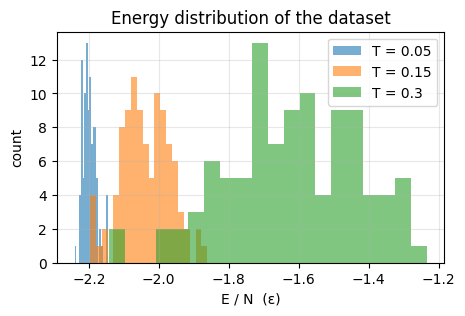

In [44]:
def langevin(R, ffun, T, nsteps, dt=0.005, gamma=1.0, every=40, rng=None):
    R = R.copy()
    v = rng.normal(scale=np.sqrt(T), size=R.shape); v -= v.mean(0)
    F = ffun(R)
    c1 = np.exp(-gamma * dt); c2 = np.sqrt((1 - c1**2) * T)
    frames = []
    for s in range(nsteps):
        v += 0.5 * dt * F;  R += 0.5 * dt * v
        v = c1 * v + c2 * rng.normal(size=R.shape)
        R += 0.5 * dt * v;  F = ffun(R);  v += 0.5 * dt * F
        if (s + 1) % every == 0:
            frames.append(R.copy())
    return frames

t0 = time.time()
rng_md = np.random.default_rng(1)
configs, energies, forces, temps = [], [], [], []
for T in (0.05, 0.15, 0.30):
    for X in langevin(R_min, ref_forces, T, 4000, rng=rng_md):
        configs.append(X); energies.append(ref_energy(X)); forces.append(ref_forces(X)); temps.append(T)
configs, energies, forces, temps = map(np.array, (configs, energies, forces, temps))
print(f"{len(configs)} configurations in {time.time()-t0:.1f} s")
print(f"energy per atom: min {energies.min()/N_at:.3f}, max {energies.max()/N_at:.3f}")
print(f"force components: std {forces.std():.2f}, max |F| {np.abs(forces).max():.1f}")

plt.figure(figsize=(5, 3))
for T in (0.05, 0.15, 0.30):
    plt.hist(energies[temps == T] / N_at, bins=20, alpha=0.6, label=f"T = {T}")
plt.xlabel("E / N  (ε)"); plt.ylabel("count"); plt.legend(); plt.title("Energy distribution of the dataset"); plt.show()

---
## Part 7. A linear Behler–Parrinello-type MLIP

### 7.1 The model
Each atom gets an energy that is linear in its descriptor vector $\mathbf G_i$:

$$
E_i=b+\mathbf w\cdot\tilde{\mathbf G}_i,\qquad
E=\sum_iE_i=Nb+\mathbf w\cdot\sum_i\tilde{\mathbf G}_i,\qquad
\tilde G_{i\mu}=\frac{G_{i\mu}-\mu_\mu}{s_\mu}.
$$

- $b$: per-atom reference energy (plays the role of $E^0_Z$ in the notes),
- $\mathbf w$: weights, one per descriptor,
- $\mu_\mu$, $s_\mu$: mean and standard deviation of descriptor $\mu$ over the training set (standardisation makes the fit well conditioned).

Forces follow by differentiating the energy:

$$
\mathbf F_k=-\nabla_{\mathbf r_k}E=-\sum_\mu w_\mu\,\frac{\partial}{\partial\mathbf r_k}\Big(\sum_i\tilde G_{i\mu}\Big).
$$

The force is **also linear in $\mathbf w$**, so energies and forces can be fitted together by one linear least-squares problem. A neural network ($E_i=\mathrm{NN}(\mathbf G_i)$) would be more flexible, but the linear model keeps every step transparent and is exactly the structure of MTP, SNAP and linear ACE.

### 7.2 Descriptor set and its Jacobian
We use 24 radial and 16 angular functions with $r_c=2.5\sigma$. The derivative $\partial(\sum_i G_{i\mu})/\partial\mathbf r_k$ (the Jacobian) is computed by central differences on the summed descriptor.

In [45]:
RC = 2.5
ETAS = np.full(24, 16.0)
RSS = np.linspace(0.8, 2.4, 24)
G4P = [(eta, zeta, lam) for eta in (0.3, 1.5) for zeta in (1, 2, 4, 16) for lam in (1, -1)]
N_G2, N_G4 = len(ETAS), len(G4P)

def descriptors(R):
    return np.hstack([g2_atoms(R, ETAS, RSS, RC), g4_atoms(R, G4P, RC)])

def descriptor_sum_and_jacobian(R, h=1e-5):
    d0 = descriptors(R).sum(axis=0)
    J = np.zeros((d0.size,) + R.shape)
    for k in range(R.shape[0]):
        for a in range(3):
            Rp = R.copy(); Rp[k, a] += h
            Rm = R.copy(); Rm[k, a] -= h
            J[:, k, a] = (descriptors(Rp).sum(0) - descriptors(Rm).sum(0)) / (2 * h)
    return d0, J

t0 = time.time()
DS, JAC = zip(*[descriptor_sum_and_jacobian(X) for X in configs])
DS, JAC = np.array(DS), np.array(JAC)
print(f"descriptors: {DS.shape},  Jacobians: {JAC.shape},  time {time.time()-t0:.1f} s")

descriptors: (300, 40),  Jacobians: (300, 40, 7, 3),  time 7.3 s


### 7.3 The loss and the design matrix
We minimise (compare Eq. (loss) in §8 of the notes)

$$
\mathcal L=\sum_{k\in\text{train}}\left[\left(\frac{\hat E_k-E_k}{N}\right)^2+w_F^2\sum_{i,\alpha}\big(\hat F_{k,i\alpha}-F_{k,i\alpha}\big)^2\right]+\lambda_{\rm reg}\|\boldsymbol\theta\|^2 ,
$$

with parameters $\boldsymbol\theta=(b,\mathbf w)$. Each configuration contributes

- one **energy row** $\big[1,\ \sum_i\tilde{\mathbf G}_i/N\big]$ with target $E_k/N$,
- $3N$ **force rows** $\big[0,\ -\partial\sum_i\tilde{\mathbf G}_i/\partial r_{k\alpha}\big]\cdot w_F$ with targets $F_{k\alpha}\,w_F$.

The ridge term $\lambda_{\rm reg}$ is added as extra rows $\sqrt{\lambda_{\rm reg}}\,\mathbf 1$ with target zero.

In [46]:
def fit_linear_mlip(train_idx, cols, use_forces=True, wF=1.0, ridge=1e-8):
    mu = DS[train_idx][:, cols].mean(0)
    sd = DS[train_idx][:, cols].std(0) + 1e-12
    rows, targets = [], []
    for k in train_idx:
        Xs = (DS[k, cols] - mu) / sd
        rows.append(np.r_[1.0, Xs / N_at]); targets.append(energies[k] / N_at)
        if use_forces:
            Js = JAC[k][cols] / sd[:, None, None]              # (n_desc, N, 3)
            frows = -Js.reshape(len(cols), -1).T               # (3N, n_desc)
            rows.extend(np.c_[np.zeros(3 * N_at), frows] * wF)
            targets.extend(forces[k].ravel() * wF)
    A, y = np.array(rows), np.array(targets)
    n_par = A.shape[1]
    A = np.vstack([A, np.sqrt(ridge) * np.eye(n_par)]); y = np.r_[y, np.zeros(n_par)]
    theta, *_ = np.linalg.lstsq(A, y, rcond=None)
    return {"b": theta[0], "w": theta[1:], "mu": mu, "sd": sd, "cols": cols}

def predict(model, dsum, J):
    c = model["cols"]
    Xs = (dsum[c] - model["mu"]) / model["sd"]
    Js = J[c] / model["sd"][:, None, None]
    E = N_at * model["b"] + model["w"] @ Xs
    F = -np.einsum("m,mia->ia", model["w"], Js)
    return E, F

def rmse(model, idx):
    dE, dF = [], []
    for k in idx:
        E, F = predict(model, DS[k], JAC[k])
        dE.append((E - energies[k]) / N_at); dF.append((F - forces[k]).ravel())
    return np.sqrt(np.mean(np.square(dE))), np.sqrt(np.mean(np.concatenate(dF)**2))

perm_all = np.random.default_rng(0).permutation(len(configs))
test_idx, pool_idx = perm_all[:100], perm_all[100:]
cols_G2 = np.arange(N_G2); cols_all = np.arange(N_G2 + N_G4)

model = fit_linear_mlip(pool_idx, cols_all, use_forces=True)
eE, eF = rmse(model, test_idx)
print(f"G2+G4, energies+forces, 200 training configs:  test RMSE  E = {1000*eE:.2f} mε/atom,  F = {eF:.4f} ε/σ")
print(f"(for scale: std of E/N = {energies.std()/N_at:.3f} ε, std of force components = {forces.std():.2f} ε/σ)")

G2+G4, energies+forces, 200 training configs:  test RMSE  E = 0.68 mε/atom,  F = 0.0105 ε/σ
(for scale: std of E/N = 0.270 ε, std of force components = 3.14 ε/σ)


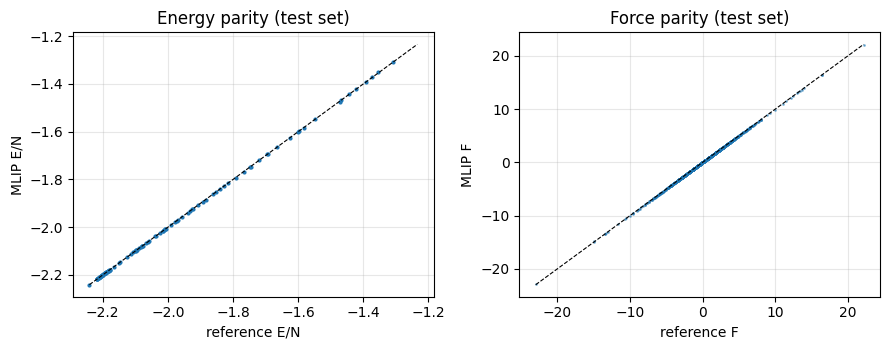

In [47]:
Ep, Fp = zip(*[predict(model, DS[k], JAC[k]) for k in test_idx])
Ep, Fp = np.array(Ep), np.array(Fp)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ax[0].plot(energies[test_idx] / N_at, Ep / N_at, ".", ms=4)
lim = [energies.min() / N_at, energies.max() / N_at]; ax[0].plot(lim, lim, "k--", lw=0.8)
ax[0].set_xlabel("reference E/N"); ax[0].set_ylabel("MLIP E/N"); ax[0].set_title("Energy parity (test set)")
ax[1].plot(forces[test_idx].ravel(), Fp.ravel(), ".", ms=2, alpha=0.5)
lim = [forces.min(), forces.max()]; ax[1].plot(lim, lim, "k--", lw=0.8)
ax[1].set_xlabel("reference F"); ax[1].set_ylabel("MLIP F"); ax[1].set_title("Force parity (test set)")
plt.tight_layout(); plt.show()

### 7.4 Learning curves: angular information and force training
We now repeat the fit for different training-set sizes and four model choices:
radial-only ($G^2$) or radial plus angular ($G^2+G^4$), trained on energies only or on energies and forces.

model                     5       10       20       50      100      200   (force RMSE, ε/σ)
G2, E only           4.2132   2.8195   0.3193   0.2147   0.1776   0.1937
G2, E+F              0.1491   0.1258   0.0993   0.0960   0.0964   0.0944
G2+G4, E only        5.2395   1.8485   0.6816   0.1418   0.1065   0.0944
G2+G4, E+F           0.0275   0.0196   0.0149   0.0120   0.0110   0.0105


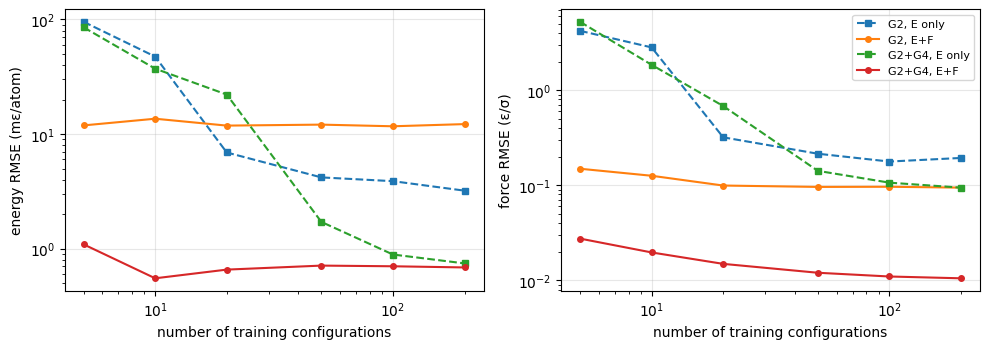

In [48]:
sizes = [5, 10, 20, 50, 100, 200]
curves = {}
for cols, cname in [(cols_G2, "G2"), (cols_all, "G2+G4")]:
    for uf in (False, True):
        key = f"{cname}, {'E+F' if uf else 'E only'}"
        curves[key] = np.array([rmse(fit_linear_mlip(pool_idx[:n], cols, uf), test_idx) for n in sizes])

print(f"{'model':18s}" + "".join(f"{n:>9d}" for n in sizes) + "   (force RMSE, ε/σ)")
for key, val in curves.items():
    print(f"{key:18s}" + "".join(f"{v:9.4f}" for v in val[:, 1]))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for key, val in curves.items():
    st = "-o" if "E+F" in key else "--s"
    ax[0].loglog(sizes, 1000 * val[:, 0], st, ms=4, label=key)
    ax[1].loglog(sizes, val[:, 1], st, ms=4, label=key)
ax[0].set_ylabel("energy RMSE (mε/atom)"); ax[1].set_ylabel("force RMSE (ε/σ)")
for a in ax: a.set_xlabel("number of training configurations")
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

**Interpretation.**

1. **Forces make training data far more valuable.** Each configuration supplies one energy but $3N=21$ force components. With forces, 10 configurations already give a better force error than 200 configurations trained on energies alone.
2. **Radial descriptors saturate.** With $G^2$ only, the force error stops improving at about 0.09 $\epsilon/\sigma$ however many data we add. The reference contains an angular term, and a model that cannot see angles cannot represent it. Adding $G^4$ removes this floor.
3. **Weights matter.** For the radial-only model, adding forces *raises* the energy error (orange curve, left panel). A model that cannot represent the PES exactly must compromise, and with `wF = 1` the many force rows dominate the loss. With the complete descriptor set ($G^2+G^4$) no compromise is needed and both errors are small.
4. Taken together, the observations are toy versions of the two big lessons from the MLIP literature: train on forces, and give the model angular (higher body-order) information.

**Try it.** Change the force weight `wF` to 0.1 and to 10 in `fit_linear_mlip`. How do the energy and force errors respond?

In [26]:
for wF_val in (0.1, 1.0, 10.0):
    model_wF = fit_linear_mlip(pool_idx, cols_all, use_forces=True, wF=wF_val)
    eE_wF, eF_wF = rmse(model_wF, test_idx)
    print(f"wF = {wF_val:4.1f} | Test RMSE: E = {1000*eE_wF:6.2f} mε/atom, F = {eF_wF:8.5f} ε/σ")

wF =  0.1 | Test RMSE: E =   0.69 mε/atom, F =  0.01641 ε/σ
wF =  1.0 | Test RMSE: E =   0.68 mε/atom, F =  0.01050 ε/σ
wF = 10.0 | Test RMSE: E =   0.66 mε/atom, F =  0.00925 ε/σ


### Response of Errors to Changing Force Weight ($w_F$)

By adjusting the force weight parameter $w_F$ in our multi-objective loss function, we control the trade-off between energy and force accuracy during fitting:

1. With $w_F = 0.1$ (Low Force Weight):
   - The fitting algorithm prioritizes matching the reference energies over the forces.
   - Result: The energy error remains low (~$0.69$ m epsilon/atom), but the force RMSE increases significantly to about $0.0164$ epsilon/sigma. This model would perform poorly in molecular dynamics, where highly accurate forces are crucial for stable trajectories.

2. With $w_F = 1.0$ (Balanced Weight):
   - A balanced trade-off where both energies and forces are weighted significantly in the loss matrix.
   - Result: Energy RMSE is practically unchanged at $0.68$ mepsilon/atom, while the force RMSE improves significantly to $0.0105$ epsilon/sigma

3. With $w_F = 10.0$ (High Force Weight):
   - The training highly prioritizes matching force components over matching energies.
   - Result: Because of the complete descriptor set ($G^2+G^4$), we do not have to heavily compromise. The force RMSE reaches its lowest value of $0.0092$ epsilon/\sigma$ and energy RMSE actually slightly improves to $0.66$ mepsilon/atom.

**Takeaway:** Adjusting $w_F$ acts as a dial to focus the model's predictive capacity. In an incomplete descriptor/basis set, high $w_F$ will drastically increase energy errors to minimize force errors, whereas a robust, complete descriptor set handles high force weights gracefully.

---
## Part 8. Molecular dynamics with the MLIP

A good test RMSE is necessary but not sufficient. We now run constant-energy (NVE) MD with **velocity Verlet**,

$$
\mathbf r(t+\Delta t)=\mathbf r(t)+\mathbf v(t)\Delta t+\frac{\mathbf F(t)}{2m}\Delta t^2,\qquad
\mathbf v(t+\Delta t)=\mathbf v(t)+\frac{\mathbf F(t)+\mathbf F(t+\Delta t)}{2m}\Delta t ,
$$

and check two things:
1. **Energy conservation.** The total energy $E_{\rm pot}+E_{\rm kin}$ should fluctuate slightly but not drift. A drift signals non-conservative or non-smooth forces.
2. **Fidelity.** Along the MLIP trajectory, we evaluate the reference energy as well. The difference measures accuracy on configurations generated by the model itself.

In [ ]:
def mlip_energy_forces(R):
    dsum, J = descriptor_sum_and_jacobian(R)
    return predict(model, dsum, J)

def ref_energy_forces(R):
    return ref_energy(R), ref_forces(R)

def velocity_verlet(R, ef, T0, nsteps, dt=0.005, seed=3):
    R = R.copy(); v = np.random.default_rng(seed).normal(scale=np.sqrt(T0), size=R.shape); v -= v.mean(0)
    E, F = ef(R); Epot, Ekin, frames = [], [], []
    for s in range(nsteps):
        v += 0.5 * dt * F; R += dt * v; E, F = ef(R); v += 0.5 * dt * F
        Epot.append(E); Ekin.append(0.5 * np.sum(v**2)); frames.append(R.copy())
    return np.array(Epot), np.array(Ekin), frames

R0 = configs[test_idx[0]]
t0 = time.time(); Ep_ml, Ek_ml, fr_ml = velocity_verlet(R0, mlip_energy_forces, 0.2, 1500); t_ml = time.time() - t0
t0 = time.time(); Ep_rf, Ek_rf, fr_rf = velocity_verlet(R0, ref_energy_forces, 0.2, 1500); t_rf = time.time() - t0
print(f"MLIP MD: {t_ml:.1f} s,  reference MD: {t_rf:.1f} s  (both are toy timings, see note below)")

E_ref_along_ml = np.array([ref_energy(X) for X in fr_ml[::10]])
time_axis = 0.005 * np.arange(1, 1501)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(time_axis, Ep_ml + Ek_ml, label="MLIP total energy")
ax[0].plot(time_axis, Ep_rf + Ek_rf, label="reference total energy")
ax[0].set_xlabel("time (τ)"); ax[0].set_ylabel("E_tot (ε)"); ax[0].legend(fontsize=8); ax[0].set_title("NVE energy conservation")
ax[1].plot(time_axis[::10], Ep_ml[::10] / N_at, label="MLIP energy")
ax[1].plot(time_axis[::10], E_ref_along_ml / N_at, "--", label="reference energy, same frames")
ax[1].set_xlabel("time (τ)"); ax[1].set_ylabel("E_pot / N"); ax[1].legend(fontsize=8); ax[1].set_title("MLIP trajectory re-evaluated")
plt.tight_layout(); plt.show()

for name, Et in [("MLIP", Ep_ml + Ek_ml), ("reference", Ep_rf + Ek_rf)]:
    print(f"{name:9s}: std of E_tot = {Et.std():.2e},  drift (last 200 - first 200 steps) = {Et[-200:].mean()-Et[:200].mean():+.2e}")
print(f"RMSE (MLIP vs reference) along the MLIP trajectory: {1000*np.sqrt(np.mean((Ep_ml[::10]-E_ref_along_ml)**2))/N_at:.2f} mε/atom")

**Note on timing.** Here the MLIP is *slower* than the reference because our reference is itself a cheap analytic function and our MLIP uses finite-difference Jacobians in pure Python. In real applications the reference is DFT, costing minutes per step, while compiled MLIPs with analytic gradients cost micro- to milliseconds. The speed-up is then $10^3$ to $10^6$.

---
## Part 9. Extrapolation: where an MLIP fails

We uniformly compress and expand the minimum-energy cluster by a factor $s$ and compare MLIP and reference energies. Compressed structures (short distances) are absent from our training data, which only contains thermal fluctuations at $T\le0.3$.

In [ ]:
min_dist_train = min(pair_geometry(X)[1][np.triu_indices(N_at, 1)].min() for X in configs)
print(f"shortest interatomic distance in the training set: {min_dist_train:.3f} σ")

Rc0 = R_min - R_min.mean(0)
scales = np.linspace(0.78, 1.25, 25)
E_ref_s, E_ml_s, dmin_s = [], [], []
for s in scales:
    Xs = Rc0 * s
    E_ref_s.append(ref_energy(Xs)); E_ml_s.append(mlip_energy_forces(Xs)[0])
    dmin_s.append(pair_geometry(Xs)[1][np.triu_indices(N_at, 1)].min())
E_ref_s, E_ml_s, dmin_s = map(np.array, (E_ref_s, E_ml_s, dmin_s))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(scales, E_ref_s / N_at, "k", label="reference"); ax[0].plot(scales, E_ml_s / N_at, "C1--", label="MLIP")
ax[0].set_xlabel("scale factor s"); ax[0].set_ylabel("E / N"); ax[0].legend()
ax[1].semilogy(dmin_s, np.abs(E_ml_s - E_ref_s) / N_at + 1e-6, "o-", ms=3)
ax[1].axvline(min_dist_train, color="C3", ls=":", label="shortest distance in training data")
ax[1].set_xlabel("shortest distance in structure (σ)"); ax[1].set_ylabel("|error| per atom"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

for s in (0.80, 0.85, 1.00, 1.20):
    i = np.argmin(np.abs(scales - s))
    print(f"s = {scales[i]:.2f}: reference {E_ref_s[i]:8.3f}, MLIP {E_ml_s[i]:8.3f}")

**Interpretation.** Inside the sampled range the two curves are indistinguishable. Once the shortest distance falls below anything in the training set, the error grows by orders of magnitude, and at $s=0.8$ the MLIP underestimates the repulsion by about 10 % (roughly $10\,\epsilon$ for the whole cluster). Practical remedies, in order of importance:

1. **Include compressed and high-temperature configurations in the training set** (rattled and strained structures, close-contact dimers).
2. **Active learning.** Monitor an uncertainty measure during MD (MTP extrapolation grade $\gamma$, committee disagreement, GPR variance) and send flagged configurations to DFT.
3. **A physical baseline** for short distances, such as a ZBL repulsion, so that the MLIP only has to learn a correction.

---
## Summary of the session

| Concept | Where you saw it |
|---|---|
| Forces are $-\nabla E$ and must be checked numerically | Part 1 |
| Linear fit in a fixed basis, train vs test error, extrapolation | Part 2 |
| Smooth cutoffs | Part 3 |
| Invariant descriptors ($G^2$, $G^4$) | Part 4 |
| Equivariant $l=1$ features, the ACE density trick | Part 5 |
| Data generation with Langevin MD | Part 6 |
| Joint energy + force training, angular information, learning curves | Part 7 |
| NVE energy conservation, fidelity along MLIP trajectories | Part 8 |
| Failure outside the training domain | Part 9 |

The assignment notebook asks you to rebuild this pipeline yourself for a different reference potential.